# Magic-state cultivation (d = 3): what the tool finds

**Cultivation** makes a good magic state by checking it. A T-type state is prepared inside a small code (here the 7-qubit colour code, which is the Steane code), and then *measured in its own basis*. If the state is right, the measurement gives the answer that earlier outcomes predict. Under noise, a wrong answer means the state is bad and the run is thrown away.

This notebook runs the three questions of the paper on the d = 3 cultivation circuit of Wan, Zhong and Zapirain (*Simulating magic state cultivation with few Clifford terms*, Quantum 10, 2134 (2026)), which follows Gidney, Shutty and Jones (arXiv:2409.17595). The circuit is copied unchanged from the authors' repository (Apache-2.0); see `circuits/cultivation/README.md`.

Part 4 draws the reduction step by step, as in the thesis, and checks every picture against the circuit diagram. Part 5 checks the tool's claims against an independent state-vector simulation of the same circuit, which involves no ZX at all.

In [1]:
%matplotlib inline
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')                       # for the test suite's state-vector simulator (Part 5)
from zxqec.qprogram import program_from_stim
from zxqec.gpf import reduce_gpf, is_leaf

text = open('circuits/cultivation/d3_cultivation.stim').read()
p, circ = program_from_stim(text, names=['first checks', 'inject', 'checks again',
                                         'double-check (T-dag, measure)', 'double-check (T, measure)'])
print(circ.qubits, "qubits,", circ.measurements, "measurements,", len(circ.detectors),
      "detectors written by the authors,", p.num_stages, "stages")
for s in range(p.num_stages):
    print("  stage", s, p.stage(s))

18 qubits, 31 measurements, 26 detectors written by the authors, 5 stages
  stage 0 first checks
  stage 1 inject
  stage 2 checks again
  stage 3 double-check (T-dag, measure)
  stage 4 double-check (T, measure)


The file is in Stim's text format, with `T` and `T_DAG` added. `program_from_stim` turns it into a program. It starts a new stage wherever a measured qubit is reset, so every measurement ends a stage.

The authors' `DETECTOR` lines are **not** used to build the program. They are kept aside, so that we can compare them with the detectors the tool derives by itself.

Below, the qubits are drawn at the positions given in the file. The seven that the code ends up on are marked; the others are helper qubits.

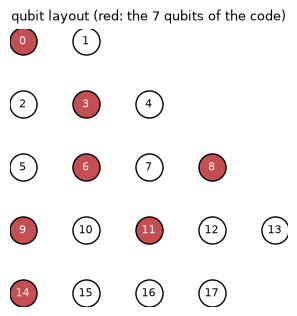

In [2]:
data = [0, 3, 6, 8, 9, 11, 14]
fig, ax = plt.subplots(figsize=(4, 3.6))
for q, xy in circ.coords.items():
    on = q in data
    ax.scatter(xy[1], -xy[0], s=380, c='#C44E52' if on else 'white', edgecolors='black', zorder=3)
    ax.text(xy[1], -xy[0], str(q), ha='center', va='center', color='white' if on else 'black', fontsize=8, zorder=4)
ax.set_title("qubit layout (red: the 7 qubits of the code)", fontsize=9); ax.axis('off'); ax.set_aspect('equal');

## Part 1. Question 1: which code, after each stage?

In [3]:
for s in range(p.num_stages):
    code = p.code_at(s)
    parts = ["[[{},{},{}]] on qubits {}{}".format(*b.parameters, list(b.qubits),
             "  (non-Clifford logical state)" if b.non_clifford else "") for b in code.blocks()]
    print("after stage {} ({}):".format(s, p.stage(s)))
    for part in parts:
        print("    " + part)

after stage 0 (first checks):
    [[8,0,None]] on qubits [0, 3, 6, 8, 9, 11, 13, 16]
after stage 1 (inject):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (non-Clifford logical state)
after stage 2 (checks again):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (non-Clifford logical state)
after stage 3 (double-check (T-dag, measure)):
    [[12,3,2]] on qubits [0, 1, 2, 3, 5, 7, 8, 9, 10, 11, 14, 15]  (non-Clifford logical state)
after stage 4 (double-check (T, measure)):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (non-Clifford logical state)


* After the **first checks** the helpers and the future code qubits are in a stabilizer state with no logical qubit (`k = 0`).
* After the **injection** the data are in a **[[7,1,3]]** code holding a non-Clifford logical state. That is the colour code with the magic state inside, found from the gates.
* After the **first half of the double-check** the tool reports a strange [[12,3,2]]. This cut falls in the middle of a T†…T sandwich, where the state is not a code state in any useful sense. That is why the double-check is grouped as one block in Part 3.
* After the **double-check** it is the [[7,1,3]] code again.

The stabilizers at the end, with signs that are measurement outcomes:

In [4]:
print(p.code_at(p.num_stages - 1).data())

[[7, 1, 3]] CSS code on qubits 0, 3, 6, 8, 9, 11, 14 (holding a non-Clifford logical state)
    stabilizer (-1)^(c[4])XIIXXXI
    stabilizer (-1)^(c[27])IIXIXXX
    stabilizer (-1)^(c[28] + c[5])IXIXXIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII

## Part 2. The detectors, and why two of them need the T gates

A *detector* is a parity of outcomes that is 0 in every noiseless run. The authors wrote 26 by hand. The tool derives its own; the next cell compares the two sets as spaces of parities.

In [5]:
from zxqec.codes.gf2 import as_matrix, rank

def span(polys, names):
    rows = []
    for d in polys:
        v = np.zeros(len(names) + 1, dtype=np.uint8)
        if isinstance(d, list):
            for n in d: v[names.index(n)] ^= 1
        else:
            for coeff, term in d.terms:
                if int(coeff) % 2:
                    if term.vars: v[names.index(term.vars[0][0].name)] ^= 1
                    else: v[-1] ^= 1
        rows.append(v)
    return as_matrix(rows, len(names) + 1)

names = ['c[{}]'.format(i) for i in range(circ.measurements)]
theirs = span(circ.detectors, names)
for gadgets in (False, True):
    res = reduce_gpf(p.quantum_graph(), gadgets=gadgets)
    on_outcomes = [d for d in res.detectors if all(str(v).startswith('c[') for v in d.free_vars())]
    ours = span(on_outcomes, names)
    missed = [i for i, d in enumerate(circ.detectors) if rank(np.concatenate([ours, span([d], names)])) > rank(ours)]
    extra = rank(np.concatenate([ours, theirs])) - rank(theirs)
    h = res.graph
    print("gadget layer simplified: {:<5} -> {} detectors on outcomes; authors' detectors not found: {}; "
          "ours not among theirs: {}; T-type gadgets left: {}".format(
          str(gadgets), rank(ours), [circ.detectors[i] for i in missed] or 'none', extra,
          sum(1 for v in h.vertices() if is_leaf(h, v))))
print("other constraints the tool reports:", [str(d) for d in res.detectors if d not in on_outcomes])

gadget layer simplified: False -> 24 detectors on outcomes; authors' detectors not found: [['c[2]', 'c[3]', 'c[5]', 'c[7]', 'c[8]', 'c[10]', 'c[11]', 'c[13]', 'c[14]', 'c[19]', 'c[20]', 'c[24]'], ['c[27]', 'c[24]']]; ours not among theirs: 0; T-type gadgets left: 15


gadget layer simplified: True  -> 26 detectors on outcomes; authors' detectors not found: none; ours not among theirs: 0; T-type gadgets left: 1
other constraints the tool reports: ['s3_r0', 's1_r0']


Reading the two lines:

* With only Clifford reasoning (first line), the tool finds **24 of the 26**. The two it misses both contain `c[24]`, the outcome of the double-check. They hold only because the T† gates before the check and the T gates after it cancel. A reduction that treats the 15 T-type gadgets as fixed cannot see that.
* With the **gadget layer simplified** (second line, the default), all 26 are found and nothing else. The 15 gadgets shrink to one.
* The last line lists two constraints on PyZX's *reset variables*. They say that resetting a qubit already in |0⟩ discards the value 0: true, and not about any measurement.

How the gadget layer is simplified is the idea of the triorthogonality check of the thesis. Each T-type gadget adds a phase that depends on the parity of some bits of the diagram. Adding all of them gives one polynomial in those bits, with coefficients modulo 2π, and this polynomial describes the whole layer exactly.

* When T† and T gates cancel, their terms cancel in the polynomial. For π/4 gadgets, "cancel" is exactly the triorthogonality condition: weights 0 mod 8, pair overlaps 0 mod 4, triple overlaps 0 mod 2.
* A bit that no term depends on any more is free again. The ordinary row reduction then turns it into a detector: here, the two missing ones.

This is a computation on a polynomial, not a search for rewrite rules. Here it leaves:

### The same check as one call

`check_detectors` compares declared detectors with the derived ones for any program. Each declared detector gets one of three answers:

* **deterministic**: it is a sum of derived detectors, so it has the same value in every noiseless run (the value is printed);
* **not deterministic**: two runs that the program allows give it different values (the two runs are returned as evidence);
* **unknown**: neither could be shown. With the gadgets held fixed, the tool does not derive the two detectors that need the T gates, and it does not find a run that breaks them either, so it does not call them wrong.

The last lines leave one result out of a declared detector, to show what a wrong detector looks like.

In [6]:
from zxqec.qprogram import check_detectors

print(check_detectors(p, circ.detectors))
print()
print(check_detectors(p, circ.detectors, gadgets=False))
print()
wrong = [list(d) for d in circ.detectors]
wrong[9] = [x for x in wrong[9] if x != 'c[12]']          # detector 9 without c[12]
bad = check_detectors(p, wrong).declared[9]
print(bad)
print("its values in the two runs returned as evidence:", [sum(run[n] for n in bad.results) % 2 for run in bad.witness])

26 declared detector(s): 26 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 26 independent detectors on its results, all sums of declared ones



26 declared detector(s): 24 deterministic (value 0), 0 not deterministic, 2 unknown
  detector 19: c[2] + c[3] + c[5] + c[7] + c[8] + c[10] + c[11] + c[13] + c[14] + c[19] + c[20] + c[24] is not a sum of the derived detectors, and no two allowed runs with different values were found: unknown
  detector 22: c[27] + c[24] is not a sum of the derived detectors, and no two allowed runs with different values were found: unknown
the program has 24 independent detectors on its results, all sums of declared ones

detector 9: c[13] + c[6] is NOT deterministic: it is 0 in one allowed run and 1 in another
its values in the two runs returned as evidence: [0, 1]


In [7]:
from zxqec.gpf import phase_polynomial
h = reduce_gpf(p.quantum_graph()).graph
poly, gadgets = phase_polynomial(h)
print("phase polynomial of what is left (units of pi):",
      {tuple(sorted(str(v[1]) if isinstance(v, tuple) else v for v in m)): str(c) for m, c in poly.items()})
for v in h.vertices():
    if is_leaf(h, v):
        (hub,) = list(h.neighbors(v))
        print("one gadget: angle", h.phase(v), "(pi units), on the parity of", len(list(h.neighbors(hub))) - 1, "spiders")

phase polynomial of what is left (units of pi): {('348',): '7/4', ('350',): '7/4', ('351',): '7/4', ('348', '350'): '1/2', ('348', '351'): '1/2', ('350', '351'): '1/2', ('348', '350', '351'): '1'}
one gadget: angle 7/4 (pi units), on the parity of 3 spiders


A single T† gadget on a parity of three spiders: the magic state itself.

## Part 3. Questions 2 and 3: the level-up table

Grouped the way the protocol is described: first checks, injection, a round of checks, and the double-check as one block.

In [8]:
fine = p.group_stages([(0, 0, 'first checks', 'state preparation'), (1, 1, 'inject T', 'injection'),
                       (2, 2, 'checks', 'syndrome extraction'), (3, 4, 'double-check', 'cultivation')])
s = p.summary(fine)
print(s.table()); print(); print(s.blocks[3].describe())

block           role                 code before  code after  logical action                                   every run?  checks
0 first checks  state preparation    none         [[8,0,?]]   a non-zero scalar                                yes         ok
1 inject T      injection            [[8,0,?]]    [[7,1,3]]   prepares T^dag|+>                                yes         ok
2 checks        syndrome extraction  [[7,1,3]]    [[7,1,3]]   I                                                yes         ok
3 double-check  cultivation          [[7,1,3]]    [[7,1,3]]   projects onto T^dag|+> / projects onto T^dag|->  no          ok

Block 3 'double-check' (cultivation) -- stages 3, 4
  code before: [[7,1,3]] on qubits 0,3,6,8,9,11,14 (non-Clifford logical content)
  code after:  [[7,1,3]] on qubits 0,3,6,8,9,11,14 (non-Clifford logical content)
  logical action: a logical measurement in the basis {T^dag|+>, T^dag|->}: T^dag|+> when c[24] = 0; T^dag|-> when c[24] = 1
  measurements: 7 (4 fixe

* **inject T** prepares T†|+⟩ in the code, in every run up to a Pauli correction.
* **checks** do nothing to the logical state, as checks should.
* **double-check** is a *logical measurement in the basis {T†|+⟩, T†|−⟩}*, whose outcome is `c[24]`. Its "every run?" is "no", because a measurement's outcome can differ between runs, and that is expected.

The measurement report explains why the check is useful. In this program, `c[24]` is *tied*: its parity with the injection outcomes `c[4], c[5], c[6], c[7], c[14]` is always 0. Those are exactly the outcomes that decide whether the injected state is T†|+⟩ or T†|−⟩. So the check measures the state in its own basis and always gets the predicted answer. Under noise, a different answer means the state went wrong, and the run is discarded. The tool reports this as the check "can reject a wrong state".

This is what we understand by *deterministic vs non-deterministic* in cultivation: `c[24]` alone is random, but its parity with earlier outcomes is deterministic.

One level up, the whole circuit is one block:

In [9]:
whole = p.level_up(fine, 0, 3, name='cultivation', role='state preparation')
print(p.summary(whole).table())
print()
print(p.logical_action().describe())

block          role               code before  code after  logical action     every run?  checks
0 cultivation  state preparation  none         [[7,1,3]]   prepares T^dag|+>  yes         ok



logical action: 0 -> 1 logical qubit(s)
  when c[5] + c[4] + c[6] + c[7] + c[14] = 0: prepares T^dag|+>
  when c[5] + c[4] + c[6] + c[7] + c[14] = 1: prepares T^dag|+> with correction Z
  deterministic up to a Pauli frame: every run implements prepares T^dag|+> followed by a Pauli correction (Z, none) that the outcomes determine


**In every noiseless run, the circuit prepares T†|+⟩ in the [[7,1,3]] colour code**, followed by a Z correction exactly when `c[4] + c[5] + c[6] + c[7] + c[14] = 1`. A Pauli correction like this is tracked, not applied. This matches the thesis's statement that d = 3 cultivation prepares |T†⟩ encoded; here it holds for every run, not just the one with all outcomes 0.

## Part 4. The same result, drawn step by step

Part 3 gives the verdict as text. This part shows how the diagram gets there, the way the thesis did it for this circuit (Figures 4.18 to 4.23): the whole circuit as a ZX-diagram, the diagram after each step of the reduction, and at the end the diagram we expect, **T†|+⟩ fed into the encoder of the colour code**. The last two pictures can be compared by eye.

Each picture is also checked against the circuit. The detectors fix 28 of the 33 Boolean variables (31 outcomes and 2 reset variables) in terms of the other 5, so exactly 32 runs can happen. For every picture and every one of these runs, PyZX contracts the picture and the circuit diagram to matrices, and the two must be equal up to a scalar. That check uses tensor contraction only, none of the rewrites it checks.

Outcomes in the labels are written *modulo the detectors*, in the earliest outcomes possible. For example `c[27]` is shown as `c[4]+c[5]+c[6]+c[7]+c[14]`, which it equals in every run. So two pictures that are equal carry the same labels.

In [10]:
import pyzx as zx
from pyzx.utils import VertexType
from zxqec.gpf import to_gpf, boolean_variables, restore_boundary_hadamards, phase_polynomial
from zxqec.spacetime.drawing import draw_program
from zx_steps import draw_layers, encoder_form, encoded_state, allowed_runs, layer_rows, output_phases

g = p.quantum_graph()                                  # the circuit as one ZX-diagram
res = reduce_gpf(g)
code = p.code_at(p.num_stages - 1).data()              # the [[7,1,3]] code of Part 1
variables = sorted(set(boolean_variables(g)) | {str(v) for c in res.constraints for v in c.free_vars()})
runs = allowed_runs(res.constraints, variables)
print(len(variables), "Boolean variables;", len(runs), "runs allowed by the detectors")

def same_as_circuit(h):
    """Equal to the circuit diagram, up to a scalar, in every allowed run (tensor contraction)."""
    return all(zx.compare_tensors(g.substitute_variables(a), h.substitute_variables(a), preserve_scalar=False)
               for a in runs)

def spiders(h):
    return sum(1 for v in h.vertices() if h.type(v) != VertexType.BOUNDARY)

33 Boolean variables; 32 runs allowed by the detectors


### Step 0. The whole circuit

370 spiders on 18 qubits, one shaded block per stage. The T† and T gates are the spiders with phases 7π/4 and π/4, and every measurement ends in a spider labelled with its outcome.

370 spiders


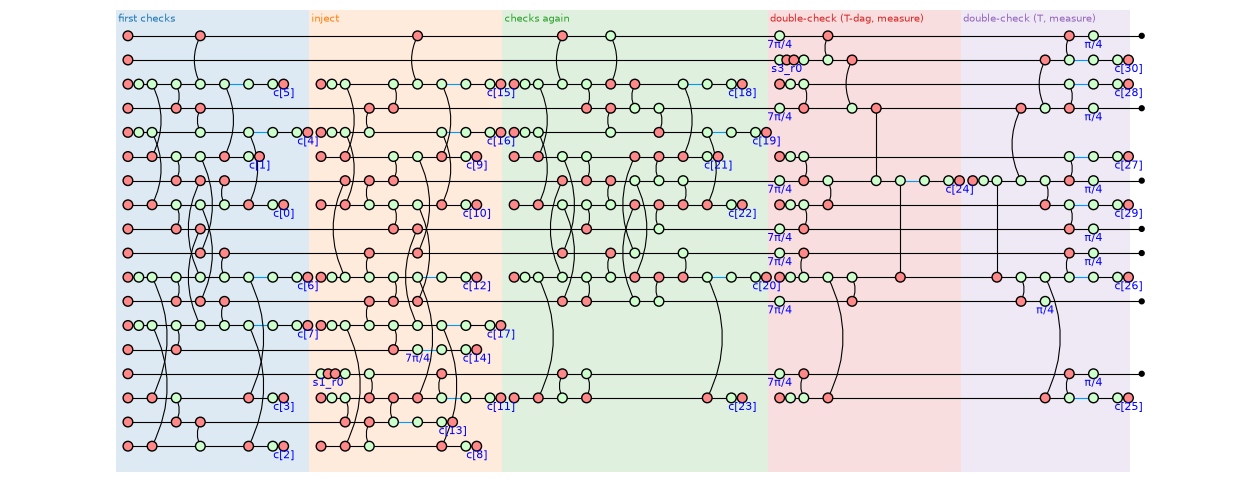

In [11]:
print(f"{spiders(g)} spiders")
draw_program(p, 0, figsize=(16, 6), show_time=False)

### Step 1. The normal form

`to_gpf` brings the diagram into two layers (the generalized parity form, Algorithm 2 of the thesis). On the left are the Z-spiders, whose bits are summed over; on the right one X-spider per output qubit. Each T-type gate has become a **phase gadget**: an X-spider (the hub) with a one-legged Z-spider carrying the phase, which acts on the parity of the Z-spiders the hub is connected to. There are 15, one per T-type gate: 7 T† and 7 T from the double-check, and the T† of the injection, whose leaf also carries the outcome `c[14]`.

The 24 detectors that hold without any help from the T gates are already found at this point: they are the factors 1 + (−1)^p left in the scalar when spiders lose their last edge.

43 spiders, 15 gadgets


equal to the circuit in all 32 runs: True


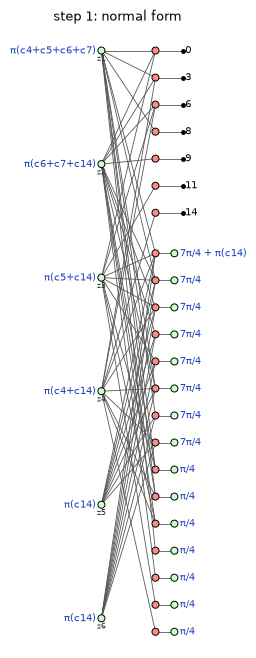

In [12]:
d1 = to_gpf(g)
ax, z1 = draw_layers(d1, title="step 1: normal form", constraints=res.constraints, qubit_names=list(code.qubits))
print(f"{spiders(d1)} spiders, {sum(1 for v in d1.vertices() if is_leaf(d1, v))} gadgets")
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(restore_boundary_hadamards(d1)))

### Step 2. The 15 gadgets in the code's variables

When a layer of ±π/4 gadgets on the physical qubits of a code can be replaced by a layer on its logical qubits. Write the parity each gadget reads in the code's variables, the k logical columns first and the stabilizer columns after; these are the rows of a matrix M. A gadget on the physical qubits has a row (P_L P_S), a gadget on the logical qubits a row (H 0). The layer (P_L P_S) equals the layer (H 0) with the opposite signs exactly when all of them together are the identity, which for π/4 gadgets is a triorthogonality condition on M.

The thesis reached this step by inserting spider-nest identities by hand. The tool adds the gadgets up as one phase polynomial (Part 2). For π/4 gadgets its coefficients mod 2 are exactly the counts of the triorthogonality condition (weights mod 8, pair overlaps mod 4, triple overlaps mod 2), so one pass over the gadgets decides it and gives H.

To see this on cultivation, change the summation variables of step 1 (as step 4 below does for the reduced diagram) so that the Z-layer is the code's logical X (`L`), its three X-type generators (`S1`, `S2`, `S3`), and two **hidden** variables (`h1`, `h2`). The normal form has six Z-spiders but only four independent rows on the outputs, so two combinations of them reach no output at all: those are the hidden variables.

equal to the circuit in all 32 runs: True
the rows of M, one per gadget, in the variables  L | S1 S2 S3 | h1 h2:
    c[14] + 7/4   1 | 0 0 0 | 1 1
            7/4   1 | 1 0 0 | 1 1
            7/4   0 | 0 1 0 | 1 1
            7/4   0 | 1 1 1 | 1 1
            7/4   0 | 1 1 0 | 1 1
            7/4   1 | 0 0 1 | 1 1
            7/4   1 | 1 0 1 | 1 1
            7/4   0 | 0 1 1 | 1 1
            1/4   1 | 1 0 0 | 0 0
            1/4   1 | 0 0 1 | 0 0
            1/4   0 | 0 1 0 | 0 0
            1/4   1 | 1 0 1 | 0 0
            1/4   0 | 1 1 1 | 0 0
            1/4   0 | 1 1 0 | 0 0
            1/4   0 | 0 1 1 | 0 0
the 7 T gates read the 7 columns of the code: True
the 7 T-dagger gates read the same 7 columns, and h1 + h2: True


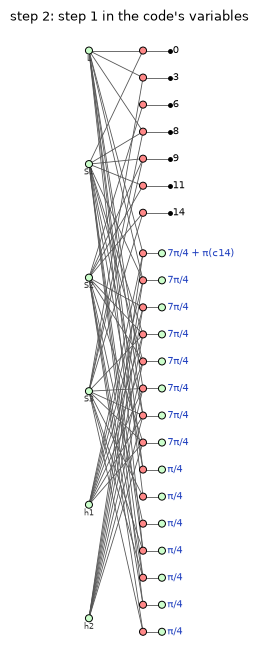

In [13]:
from fractions import Fraction
from zxqec.gpf.gadgets import _xor_terms

rows = [list(code.logical_x[0].x)] + [list(r) for r in code.sx]
m1 = encoder_form(d1, rows, fuse=False)                        # step 1 in the code's variables
zs1 = sorted(v for v in m1.vertices() if m1.type(v) == VertexType.Z and not is_leaf(m1, v))
var = dict(zip(zs1, ['L', 'S1', 'S2', 'S3', 'h1', 'h2']))
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(m1))
ax, _ = draw_layers(m1, title="step 2: step 1 in the code's variables", labels=False,
                    qubit_names=list(code.qubits), znames=var)

gadget_rows = []
print("the rows of M, one per gadget, in the variables  L | S1 S2 S3 | h1 h2:")
for leaf in sorted(v for v in m1.vertices() if is_leaf(m1, v)):
    (hub,) = list(m1.neighbors(leaf))
    r = tuple(int(m1.connected(hub, z)) for z in zs1)
    gadget_rows.append((str(m1.phase(leaf)), r))
    print("   {:>12}   {} | {} | {}".format(str(m1.phase(leaf)), r[0], ' '.join(map(str, r[1:4])), ' '.join(map(str, r[4:]))))

columns = {tuple(int(row[j]) for row in rows) for j in range(code.n)}     # (P_L P_S) of each code qubit
t_rows = {r[:4] for a, r in gadget_rows if a == '1/4'}
t_dag_rows = {r[:4] for a, r in gadget_rows if a == '7/4' and r[4:] == (1, 1)}
print("the 7 T gates read the 7 columns of the code:", t_rows == columns)
print("the 7 T-dagger gates read the same 7 columns, and h1 + h2:", t_dag_rows == columns)

So the **7 T gates** of the double-check read the seven columns (P_L P_S) of the code, one per code qubit: that is transversal T. The **7 T† gates** read the same seven columns and also `h1 + h2`. The **T† of the injection** reads `L`, and also `h1 + h2`; its leaf carries the outcome `c[14]`.

Adding the 15 gadgets up:

In [14]:
poly, _ = phase_polynomial(m1)
name = lambda v: var[v[1]] if isinstance(v, tuple) else v
pauli = {m: c for m, c in poly.items() if c == 1 and sum(isinstance(v, tuple) for v in m) == 1}
rest = {m: c for m, c in poly.items() if m not in pauli}
print("phase polynomial apart from Pauli terms (units of pi):",
      {'*'.join(sorted(map(name, m))): str(c) for m, c in rest.items()})
print("the same as one T-dagger gadget on L alone, i.e. H = (1):", rest == _xor_terms([('z', zs1[0])], Fraction(7, 4)))
print("Pauli terms:", sorted('*'.join(sorted(map(name, m))) for m in pauli))
print()
for z in zs1[4:]:
    extra = ' + '.join(sorted(v for m in pauli if ('z', z) in m for v in m if not isinstance(v, tuple)))
    print("summing over {}: its phase is pi({}), plus pi({}) from above -> the detector {} + {} = 0".format(
        var[z], m1.phase(z), extra, m1.phase(z), extra))

phase polynomial apart from Pauli terms (units of pi): {'L': '7/4'}
the same as one T-dagger gadget on L alone, i.e. H = (1): True
Pauli terms: ['L*c[14]', 'c[14]*h1', 'c[14]*h2']

summing over h1: its phase is pi(c[4] + c[5] + c[6] + c[7] + c[24]), plus pi(c[14]) from above -> the detector c[4] + c[5] + c[6] + c[7] + c[24] + c[14] = 0
summing over h2: its phase is pi(c[4] + c[5] + c[6] + c[7] + c[27]), plus pi(c[14]) from above -> the detector c[4] + c[5] + c[6] + c[7] + c[27] + c[14] = 0


Everything cancels except 7π/4 on `L`: the 15 gadgets are **one T† gadget on the logical variable**, H = (1), plus the Pauli terms π·`c[14]`·(L + h1 + h2). The hidden variables are left with Pauli phases only, so their sums can be done: each gives 1 + (−1)^p, which is zero unless the parity p is 0. The two parities are the two detectors of Part 2 that need the T gates.

PyZX's own rewrite rules apply identities of bounded size, and do not find this cancellation:

In [15]:
import time
h0 = g.substitute_variables(runs[0])                             # one allowed run, outcomes fixed
t0 = time.perf_counter(); f = h0.copy(); zx.full_reduce(f); t_pyzx = time.perf_counter() - t0
t0 = time.perf_counter(); r1 = reduce_gpf(g); t_ours = time.perf_counter() - t0
print(f"PyZX full_reduce, one run:                  {zx.tcount(h0)} T-type gates -> {zx.tcount(f)}   ({t_pyzx * 1000:.0f} ms)")
print(f"reduce_gpf with the gadget step, all runs:  {sum(1 for v in d1.vertices() if is_leaf(d1, v))} gadgets -> "
      f"{sum(1 for v in r1.graph.vertices() if is_leaf(r1.graph, v))}   ({t_ours * 1000:.0f} ms)")

PyZX full_reduce, one run:                  15 T-type gates -> 15   (21 ms)
reduce_gpf with the gadget step, all runs:  15 gadgets -> 1   (40 ms)


### Step 3. The reduced diagram

What `reduce_gpf` returns: 4 Z-spiders, the 7 output X-spiders, and the single T† gadget.

13 spiders; 26 detectors on outcomes


equal to the circuit in all 32 runs: True


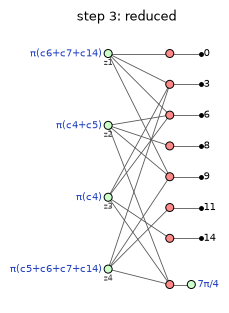

In [16]:
d2 = res.graph
ax, z2 = draw_layers(d2, title="step 3: reduced", constraints=res.constraints, qubit_names=list(code.qubits))
outcome_detectors = [c for c in res.detectors if not any(v.name.startswith('s') for v in c.free_vars())]
print(f"{spiders(d2)} spiders; {len(outcome_detectors)} detectors on outcomes")
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(res.to_graph()))

The 4 Z-spiders are one logical qubit and three X-type stabilizers of the code, but in a mixed basis: the T† gadget reads the parity of three of them.

### Step 4. A change of summation variables

The bits of the Z-spiders are summed over, so any invertible change of these variables gives the same map. We choose the one that makes the rows of the Z-layer the code's logical X (on qubits 0, 3, 8) and its three X-type generators, as printed in Part 1. The phases and the gadget follow the change (`zx_steps.encoder_form`). The gadget then reads the logical spider alone, and fuses into it as a phase: this is the right-hand side, with H = (1).

In [17]:
rows = [list(code.logical_x[0].x)] + [list(r) for r in code.sx]
d3 = encoder_form(d2, rows)
print("equal to the circuit in all", len(runs), "runs:", same_as_circuit(d3))

equal to the circuit in all 32 runs: True


### Step 5. The diagram we expect

Now build the expected diagram from the code alone, without the reduced diagram: the ideal encoder of the [[7,1,3]] code of Part 1 (`code.encoder()`), applied to T†|+⟩ followed by the Z correction of Part 3, i.e. `Z` when `c[4]+c[5]+c[6]+c[7]+c[14] = 1`. Left, step 4; right, the expected diagram.

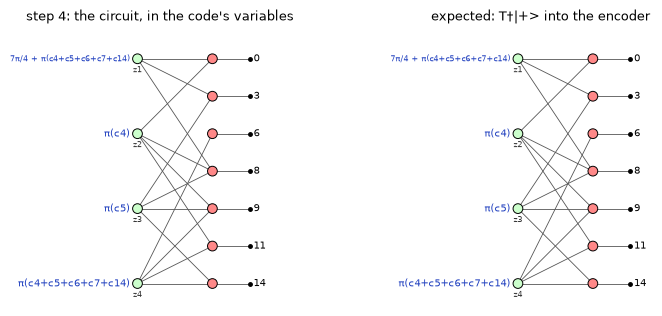

expected diagram equal to the circuit in all 32 runs: True
same spiders, edges and labels as step 4: True
the code is self-dual (X and Z stabilizers on the same supports): True


In [18]:
d4 = encoded_state(code, Fraction(7, 4), correction=['c[4]', 'c[5]', 'c[6]', 'c[7]', 'c[14]'])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
draw_layers(d3, ax=axes[0], title="step 4: the circuit, in the code's variables", constraints=res.constraints,
            qubit_names=list(code.qubits))
draw_layers(d4, ax=axes[1], title="expected: T†|+> into the encoder", constraints=res.constraints,
            qubit_names=list(code.qubits))
plt.show()
print("expected diagram equal to the circuit in all", len(runs), "runs:", same_as_circuit(d4))
print("same spiders, edges and labels as step 4:",
      layer_rows(d3, res.constraints) == layer_rows(d4, res.constraints)
      and output_phases(d3, res.constraints) == output_phases(d4, res.constraints))

from zxqec.codes import PauliString
swapped = [PauliString.from_arrays(s.z, s.x) for s in code.stabilizers]     # X <-> Z in every stabilizer
print("the code is self-dual (X and Z stabilizers on the same supports):", all(code.contains(s) for s in swapped))

The two pictures are the same: the logical spider carries 7π/4 (the T†) plus π times the correction parity, the three stabilizer spiders carry the signs of the checks, and the edges are the logical X and the three generators. A self-dual [[7,1,3]] CSS code is the Steane code up to the order of its qubits (its classical code is the [7,4,3] Hamming code), so this is the colour code of the paper.

| step | diagram | spiders | T-type gadgets | equal to the circuit in all 32 runs |
|---|---|---|---|---|
| 0 | the circuit | 370 | (15 T-type gates) | (itself) |
| 1 | normal form | 43 | 15 | yes |
| 2 | the same, in the code's variables | 43 | 15 | yes |
| 3 | reduced | 13 | 1 | yes |
| 4 | same, in the code's variables | 11 | 0 (fused into the logical spider) | yes |
| 5 | expected: T†\|+⟩ into the encoder | 11 | 0 | yes |

## Part 5. An independent check

The claims above come from the ZX pipeline. To check them without it, the next cell runs the **same Stim circuit** through a plain state-vector simulator (18 qubits; the simulator of our test suite, `tests/statevector.py`). It samples measurement outcomes with the correct probabilities, and in each run it tests:

1. every detector the authors wrote holds;
2. every stabilizer the tool reported has exactly the sign the tool predicts from that run's outcomes;
3. the logical Bloch vector, measured with the tool's logical operators, is T†|+⟩ after the tool's Pauli correction.

In [19]:
from tests.statevector import run, expectation
from zxqec.gpf import evaluate_phase

code = p.code_at(p.num_stages - 1).data()
q = [int(x) for x in code.qubits]
lx, lz = code.logical_x[0].letters, code.logical_z[0].letters
ly = ''.join({('X','Z'): 'Y', ('X','I'): 'X', ('I','Z'): 'Z', ('I','I'): 'I'}[(a, b)] for a, b in zip(lx, lz))
sign_y = (1j * (-1j) ** ly.count('Y')).real            # i * Xbar * Zbar = sign_y * (the string ly)
t_dag_plus = np.array([np.cos(np.pi / 4), -np.sin(np.pi / 4), 0.0])

rng = np.random.default_rng(2026); worst = 0.0; classes = []
for r in range(30):
    state, outs = run(circ, rng)
    a = {'c[{}]'.format(i): o for i, o in enumerate(outs)}
    assert all(sum(outs[int(n[2:-1])] for n in d) % 2 == 0 for d in circ.detectors)
    for st in code.stabilizers:
        want = (-1) ** (st.sign if isinstance(st.sign, int) else evaluate_phase(st.sign, a))
        worst = max(worst, abs(expectation(state, st.letters, q) - want))
    flip = (outs[4] + outs[5] + outs[6] + outs[7] + outs[14]) % 2
    classes.append(flip)
    bloch = np.array([expectation(state, lx, q).real, sign_y * expectation(state, ly, q).real, expectation(state, lz, q).real])
    worst = max(worst, float(np.abs(bloch - t_dag_plus * (np.array([-1, -1, 1]) if flip else 1)).max()))
print("30 sampled runs ({} with the Z correction): all 26 declared detectors held; largest deviation from "
      "the tool's predictions: {:.1e}".format(sum(classes), worst))

30 sampled runs (12 with the Z correction): all 26 declared detectors held; largest deviation from the tool's predictions: 3.3e-16


## Summary, and what this does not show

| question | the tool's answer | checked by |
|---|---|---|
| which code? | [[7,1,3]] colour code after injection and after the double-check, signs given by outcomes | simulation: each stabilizer has the predicted sign |
| detectors | all 26 the authors wrote, and no others; two of them need the gadget layer | comparison with the authors' `DETECTOR` lines |
| what does it do? | prepares T†\|+⟩, with a Z correction on a known parity of outcomes | simulation: the logical Bloch vector |
| the double-check | a logical measurement in {T†\|+⟩, T†\|−⟩}, whose outcome is predicted by the injection outcomes | measurement report; simulation |
| the reduction, drawn | circuit → normal form with 15 gadgets → one T† gadget → T†\|+⟩ into the encoder of the colour code | every picture contracted against the circuit, in all 32 allowed runs |

What this does **not** show: anything about noise, such as how often cultivation rejects a state or how good the accepted states are; and anything about larger distances. Both are outside what the tool does today.